<a href="https://colab.research.google.com/github/nusaibuhh/daily-git/blob/main/ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simple Linear Regression

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

In [ ]:
df = pd.read_csv("/content/homeprices - Sheet1.csv")
df

,Area,Price
0,2600,55000
1,3000,56500
2,3200,61000
3,3600,68000
4,4000,72500


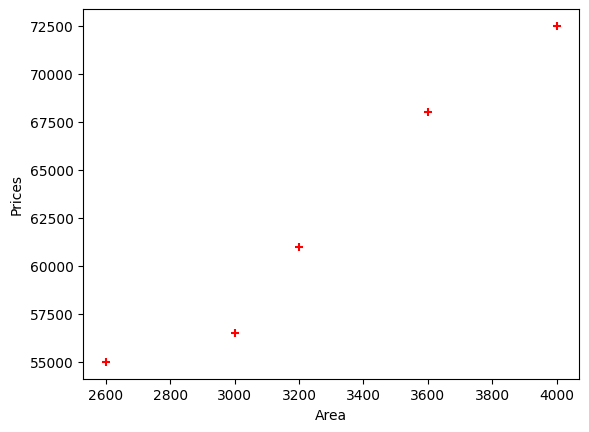

In [ ]:
%matplotlib inline
plt.xlabel('Area')
plt.ylabel('Prices')
plt.scatter(df.Area, df.Price, color='red', marker='+')


In [ ]:
reg = linear_model.LinearRegression()
reg.fit(df[['Area']], df.Price)

LinearRegression()

In [ ]:
reg.predict([[3300]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([62871.57534247])

In [ ]:
#reg.coef_
reg.intercept_

np.float64(18061.64383561643)

In [ ]:
d = pd.DataFrame(
    {'Area' : [1000, 1500, 2300, 3540, 4120]},
    index = [1,2,3,4,5]
)
d

,Area
1,1000
2,1500
3,2300
4,3540
5,4120


In [ ]:
p = reg.predict(d)
d['Prices'] = p
d

,Area,Prices
1,1000,31640.410959
2,1500,38429.794521
3,2300,49292.808219
4,3540,66130.479452
5,4120,74006.164384


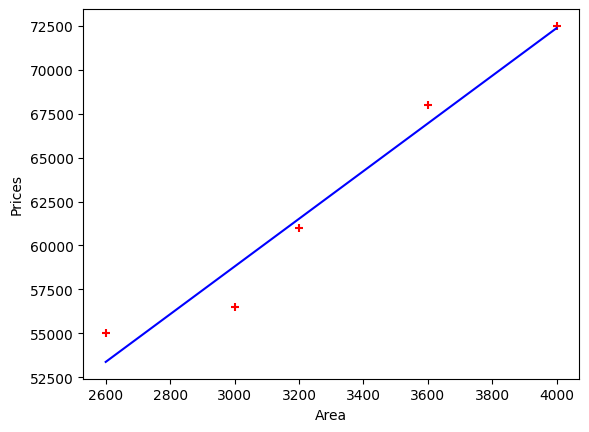

In [ ]:
%matplotlib inline
plt.xlabel('Area')
plt.ylabel('Prices')
plt.scatter(df.Area, df.Price, color='red', marker='+')
plt.plot(df.Area, reg.predict(df[['Area']]), color='blue')

# Multivariate Regression

In [ ]:
import pandas as pd
import numpy as np
from sklearn import linear_model

In [ ]:
df = pd.DataFrame(
    {'Area' : [1000, 1500, 2300, 3540, 4120],
     'Bedrooms' : [3, 4, np.nan, 3, 5],
     'Age' : [20, 15, 18, 30, 8],
     'price': [5500, 5650, 6100, 5950, 7600]},
    index = [1,2,3,4,5]
)
df

,Area,Bedrooms,Age,price
1,1000,3.0,20,5500
2,1500,4.0,15,5650
3,2300,NaN,18,6100
4,3540,3.0,30,5950
5,4120,5.0,8,7600


In [ ]:
import math
median_bed =  math.floor(df.Bedrooms.median())
median_bed

3

In [ ]:
df['Bedrooms'] = df['Bedrooms'].fillna(median_bed)
df

,Area,Bedrooms,Age,price
1,1000,3.0,20,5500
2,1500,4.0,15,5650
3,2300,3.0,18,6100
4,3540,3.0,30,5950
5,4120,5.0,8,7600


In [ ]:
reg = linear_model.LinearRegression()
reg.fit(df[['Area', 'Bedrooms', 'Age']], df.price)

LinearRegression()

In [ ]:
reg.coef_

array([   0.54494122, -207.05292815,  -76.22129008])

In [ ]:
reg.intercept_

np.float64(6934.624498172715)

In [ ]:
reg.predict([[3000,3,15]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([6804.97002538])

Practice

In [ ]:
d = pd.DataFrame(
    {'Experience' : [np.nan, np.nan, 'Five', 'Two', 'Seven', 'Three', 'Ten', 'Eleven'],
     'test_score' : [8, 8, 6, 10, 9, 7, np.nan, 7],
     'interview_score' : [9, 6, 7, 10, 6, 10, 7, 8],
     'salary': [5000, 4500, 6000, 6550, 7000, 6200, 7200, 8000]},
    index = [1,2,3,4,5,6,7,8]
)
d

,Experience,test_score,interview_score,salary
1,NaN,8.0,9,5000
2,NaN,8.0,6,4500
3,Five,6.0,7,6000
4,Two,10.0,10,6550
5,Seven,9.0,6,7000
6,Three,7.0,10,6200
7,Ten,NaN,7,7200
8,Eleven,7.0,8,8000


In [ ]:
!pip install word2number

  Preparing metadata (setup.py) ... done
  Created wheel for word2number: filename=word2number-1.1-py3-none-any.whl size=5657 sha256=3aa08bb5d45716df5d94ebd8386ccc3c93fba6b78755d1fb25977f4a8c6118b2
  Stored in directory: /root/.cache/pip/wheels/aa/2b/71/ede4a3c3520a8374778c16c345e0e78e25d1ffe38f4c5c1e8a
Successfully built word2number


In [ ]:
from word2number import w2n

# Example usage:
print(w2n.word_to_num("five"))
print(w2n.word_to_num("eleven"))

5
11


In [ ]:
from word2number import w2n

# Fill NaN values in Experience with 'zero'
d['Experience'] = d['Experience'].fillna('zero')

# Ensure all values are converted to string before applying word_to_num
d['Experience'] = d['Experience'].astype(str).apply(w2n.word_to_num)

d

,Experience,test_score,interview_score,salary
1,0,8.0,9,5000
2,0,8.0,6,4500
3,5,6.0,7,6000
4,2,10.0,10,6550
5,7,9.0,6,7000
6,3,7.0,10,6200
7,10,NaN,7,7200
8,11,7.0,8,8000


In [ ]:
import math
median_exp =  math.floor(d.Experience.median())
median_exp

4

In [ ]:
# Replace 0 values in the Experience column with the calculated median
d['Experience'] = d['Experience'].replace(0, median_exp)
d

,Experience,test_score,interview_score,salary
1,4,8.0,9,5000
2,4,8.0,6,4500
3,5,6.0,7,6000
4,2,10.0,10,6550
5,7,9.0,6,7000
6,3,7.0,10,6200
7,10,NaN,7,7200
8,11,7.0,8,8000


In [ ]:
median_score = math.floor(d.test_score.median())
median_score
d['test_score'] = d['test_score'].fillna(median_score)
d

,Experience,test_score,interview_score,salary
1,4,8.0,9,5000
2,4,8.0,6,4500
3,5,6.0,7,6000
4,2,10.0,10,6550
5,7,9.0,6,7000
6,3,7.0,10,6200
7,10,8.0,7,7200
8,11,7.0,8,8000


In [ ]:
reg = linear_model.LinearRegression()
reg.fit(d[['Experience','test_score','interview_score']], d.salary)

LinearRegression()

In [ ]:
reg.predict([[12,10,10]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([9508.03081147])

# Gradient Descent, Cost Function

mse = 1/n * sum of ((y - y-pred)**2)

In [2]:
import numpy as np

In [23]:
def gradient_descent(x, y):
  m_init = b_init = 0
  iterations = 90
  n = len(x)
  l_rate = 0.05
  for i in range(iterations):
    y_pred = m_init * x + b_init
    mse = (1/n) * sum([val**2 for val in (y-y_pred)])
    md = -(2/n) * sum(x*(y-y_pred))
    bd = -(2/n) * sum(y-y_pred)
    m_init = m_init - l_rate * md
    b_init = b_init - l_rate * bd
    print("m {}, b {}, cost {}, iteration {}".format(m_init, b_init, mse, i))

In [10]:
x = np.array([1,2,3,4,5])
y = np.array([5,7,9,11,13])

gradient_descent(x,y)

m 4.96, b 1.44, cost 89.0, iteration 0
m 0.4991999999999983, b 0.26879999999999993, cost 71.10560000000002, iteration 1
m 4.451584000000002, b 1.426176000000001, cost 56.8297702400001, iteration 2
m 0.892231679999997, b 0.5012275199999995, cost 45.43965675929613, iteration 3
m 4.041314713600002, b 1.432759910400001, cost 36.35088701894832, iteration 4
m 1.2008760606719973, b 0.7036872622079998, cost 29.097483330142282, iteration 5
m 3.7095643080294423, b 1.4546767911321612, cost 23.307872849944438, iteration 6
m 1.4424862661541864, b 0.881337636696883, cost 18.685758762535738, iteration 7
m 3.4406683721083144, b 1.4879302070713722, cost 14.994867596913156, iteration 8
m 1.6308855378034224, b 1.0383405553279617, cost 12.046787238456794, iteration 9
m 3.2221235247119777, b 1.5293810083298451, cost 9.691269350698109, iteration 10
m 1.7770832372205707, b 1.1780607551353204, cost 7.8084968312098315, iteration 11
m 3.0439475772474127, b 1.5765710804477953, cost 6.302918117062937, iteration 1

In [19]:
import pandas as pd
df = pd.DataFrame(
    {'Name' : ["A", "B", "C", "D", "E", "F", "G", "H", "J","I"],
     'Math' : [92, 56, 88, 70, 80, 49, 65, 35, 66, 67],
     'CS' : [98, 68, 81, 80, 83, 52, 66, 30, 68, 73]},
    index = [1,2,3,4,5,6,7,8,9,10]
)
df

,Name,Math,CS
1,A,92,98
2,B,56,68
3,C,88,81
4,D,70,80
5,E,80,83
6,F,49,52
7,G,65,66
8,H,35,30
9,J,66,68
10,I,67,73


In [24]:
x = np.array(df['Math'])
y = np.array(df['CS'])
gradient_descent(x, y)

m 494.5900000000001, b 6.990000000000001, cost 5199.1, iteration 0
m -233196.41919999997, b -3290.580200000001, cost 1153601380.3772602, iteration 1
m 110184464.09581596, b 1554797.5480759998, cost 257542454226257.56, iteration 2
m -52061526391.8946, b -734632895.3767823, cost 5.749656569942051e+19, iteration 3
m 24598772415766.72, b 347109826699.0069, cost 1.2836155798701486e+25, iteration 4
m -1.1622778782850056e+16, b -164007400893285.6, cost 2.865682387882143e+30, iteration 5
m 5.491696266456336e+18, b 7.749255560863443e+16, cost 6.397659608532214e+35, iteration 6
m -2.594794966545439e+21, b -3.6614787759880552e+19, cost 1.428282793645305e+41, iteration 7
m 1.226025728978301e+24, b 1.7300277067539643e+22, cost 3.188653137942207e+46, iteration 8
m -5.792901202201606e+26, b -8.174281620214266e+24, cost 7.118694476574112e+51, iteration 9
m 2.7371125699322698e+29, b 3.8623011496124807e+27, cost 1.589254423687814e+57, iteration 10
m -1.2932699797527982e+32, b -1.8249151256801052e+30, co

/tmp/ipykernel_1491/3916319504.py:8: RuntimeWarning: overflow encountered in scalar power
  mse = (1/n) * sum([val**2 for val in (y-y_pred)])
